# Lab: diagnosticando e selecionando modelos para o preço de casas na Califórnia

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/model-selection/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** O alvo é o valor mediano das casas de cada distrito. Você espera uma distribuição simétrica ou com cauda longa? E se o censo tivesse um teto para os valores altos, o que isso faria com o erro de qualquer modelo?

**Resposta (antes de rodar):** Espero uma distribuicao com cauda longa para a direita: a maioria
dos distritos deve ter valores medios moderados, mas alguns distritos caros (perto de grandes
cidades) devem puxar a media bem acima da mediana. Quanto ao teto do censo (valores truncados em
US$ 500.001): isso deve criar um acumulo artificial de distritos empilhados exatamente nesse valor
(censura a direita). Para qualquer modelo, isso gera um vies que nenhuma coluna disponivel pode
corrigir: os distritos realmente caros (que valeriam mais que 500.001) ficam com o mesmo rotulo dos
que valem exatamente 500.001, entao o erro nesses casos tem um piso que nao depende da qualidade do
modelo.

In [1]:
import numpy as np
import pandas as pd

url = 'https://raw.githubusercontent.com/hsandmann/biblio/refs/heads/main/ml/aula02/housing.csv'
df = pd.read_csv(url)
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
print(df['median_house_value'].describe().round(0))
print('districts at the 500,001 cap:', (df['median_house_value'] >= 500_001).sum())

(20640, 10)
total_bedrooms    207
dtype: int64
count     20640.0
mean     206856.0
std      115396.0
min       14999.0
25%      119600.0
50%      179700.0
75%      264725.0
max      500001.0
Name: median_house_value, dtype: float64
districts at the 500,001 cap: 965


**Resposta (depois de rodar):** Confirmado em parte — `df.shape` é (20.640, 10), com 207
valores ausentes em `total_bedrooms`. O alvo tem cauda longa: média **206.856** bem acima da
mediana **179.700** (diferença de 27.156), confirmando a assimetria para a direita prevista. E a
hipótese do teto se confirma: **965** distritos (4,7% dos 20.640) estão empilhados exatamente no
valor 500.001 — o máximo da coluna. Esses 965 casos repetem o mesmo rótulo mesmo sendo preços
"reais" diferentes, então nenhum modelo pode diferenciá-los usando apenas essas colunas; eles
colocam um piso de erro que persiste mesmo com o melhor modelo possível.

## Passo 2 — trancar o conjunto de teste, um `cv` para tudo

**Preveja.** O baseline prevê o mesmo preço para todo distrito. A raiz do erro quadrático médio (RMSE, do inglês *root mean squared error*) dele deve ficar perto de qual estatística dos preços que você viu no passo 1?

**Resposta (antes de rodar):** O baseline (`DummyRegressor`, que preve sempre a media do
treino) erra, em RMSE, algo proximo do desvio-padrao do alvo -- nao da media nem da mediana, porque o
RMSE de um preditor constante igual a media e, por definicao, o proprio desvio-padrao da variavel
(a raiz da variancia). Pela distribuicao vista no passo 1 (com cauda longa e o teto em 500.001),
espero algo da ordem de US$ 110-120 mil.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

X = df.drop(columns='median_house_value')
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

counts = ['total_rooms', 'total_bedrooms', 'population', 'households']      # assimétricas: log nelas
others = ['longitude', 'latitude', 'housing_median_age', 'median_income']
pre = ColumnTransformer([
    ('counts', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                             StandardScaler()), counts),
    ('others', StandardScaler(), others),
    ('ocean', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity']),
])
cv = KFold(n_splits=5, shuffle=True, random_state=42)                      # um cv para tudo


def rmse(model):
    """RMSE médio de treino e de validação nos 5 folds e o desvio-padrão da validação entre folds."""
    r = cross_validate(model, X_train, y_train, cv=cv, return_train_score=True,
                       scoring='neg_root_mean_squared_error')
    return abs(r['train_score'].mean()), abs(r['test_score'].mean()), r['test_score'].std()


print(X_train.shape, X_test.shape)
print('dummy (predicts the mean): train %.0f · validation %.0f ± %.0f' % rmse(DummyRegressor()))

(16512, 9) (4128, 9)
dummy (predicts the mean): train 114784 · validation 114793 ± 1401


**Resposta (depois de rodar):** Confirmado — `X_train` tem **16.512** linhas e `X_test` tem
**4.128** (80/20 de 20.640). O `DummyRegressor` (sempre prevê a média do treino) erra, em RMSE,
**114.784** no treino e **114.793 ± 1.401** na validação — muito perto do desvio-padrão do alvo
(115.396, visto no `describe` do Passo 1), exatamente como esperado: o RMSE de um preditor
constante igual à média é, por definição, o próprio desvio-padrão da amostra.

## Passo 3 — três famílias, um primeiro diagnóstico

**Preveja.** Uma árvore sem limite de profundidade e uma regressão linear: qual delas vai ter o menor erro de treino? E a maior distância entre treino e validação?

**Resposta (antes de rodar):** A arvore sem limite de profundidade deve ter o menor erro de
treino -- ela pode crescer folhas ate isolar cada ponto de treino, entao seu RMSE de treino deve
chegar bem perto de 0 (sobreajuste total). Por isso mesmo, ela tambem deve ter a maior distancia
entre treino e validacao (maior *gap*): um erro de treino quase nulo com um erro de validacao bem
maior que o da regressao linear ou do k-NN.

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

candidates = {
    'linear': make_pipeline(pre, LinearRegression()),
    'k-NN (k=5)': make_pipeline(pre, KNeighborsRegressor()),
    'tree (no limits)': make_pipeline(pre, DecisionTreeRegressor(random_state=42)),
}
print(f"{'':17s} {'train':>7s} {'valid':>7s} {'gap':>7s}")
for name, model in candidates.items():
    tr, va, sd = rmse(model)
    print(f"{name:17s} {tr:7.0f} {va:7.0f} {va - tr:7.0f}")

                    train   valid     gap


linear              66369   66460      91


k-NN (k=5)          48898   59967   11069


tree (no limits)        0   67266   67266


**Resposta (depois de rodar):** Confirmado nos dois pontos. A árvore sem limites tem o
menor erro de treino (**0**, ela isola cada linha de treino) e também o maior gap (**67.266**,
igual ao próprio erro de validação, já que o treino é 0). A regressão linear tem o menor gap de
todos (**91**, entre 66.369 de treino e 66.460 de validação) — ela está do lado do viés, não da
variância. O k-NN fica no meio: treino 48.898, validação 59.967, gap 11.069.

**Simulação: a variância, vista de perto.** A distância entre treino e validação é um sintoma; a variância é a causa: o quanto o modelo muda quando a amostra muda. Meça isso diretamente. Divida `X_train` em três partes disjuntas, A, B e C; treine cada família duas vezes, uma em A e outra em B, e compare as previsões das duas versões nos mesmos distritos de C. Qual família muda mais de uma amostra para outra?

In [4]:
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error

rng = np.random.RandomState(0)
perm = rng.permutation(len(X_train))
A_idx, B_idx, C_idx = np.array_split(perm, 3)
XA, yA = X_train.iloc[A_idx], y_train.iloc[A_idx]
XB, yB = X_train.iloc[B_idx], y_train.iloc[B_idx]
XC, yC = X_train.iloc[C_idx], y_train.iloc[C_idx]
print(f"A: {len(XA)} · B: {len(XB)} · C: {len(XC)}")

print(f"{'':17s} {'RMSE em C (A)':>14s} {'RMSE em C (B)':>14s} {'|predA - predB| medio':>22s}")
for name, model in candidates.items():
    model_A = clone(model).fit(XA, yA)
    model_B = clone(model).fit(XB, yB)
    predA = model_A.predict(XC)
    predB = model_B.predict(XC)
    rmseA = root_mean_squared_error(yC, predA)
    rmseB = root_mean_squared_error(yC, predB)
    diff = np.abs(predA - predB).mean()
    print(f"{name:17s} {rmseA:14.0f} {rmseB:14.0f} {diff:22.0f}")

A: 5504 · B: 5504 · C: 5504
                   RMSE em C (A)  RMSE em C (B)  |predA - predB| medio
linear                     67682          67810                   2518


k-NN (k=5)                 63832          64414                  28284
tree (no limits)           73693          74229                  54060


**Resposta:** Dividindo `X_train` em três partes disjuntas de 5.504 linhas cada (A, B, C) e
comparando as previsões de duas versões de cada família (uma treinada em A, outra em B) nos mesmos
distritos de C: a árvore sem limites muda muito mais de uma amostra para outra — `|predA − predB|`
médio de **54.060** — contra **28.284** do k-NN e só **2.518** da regressão linear. A ordem
(árvore ≫ k-NN ≫ linear) confirma exatamente o que o Passo 3 media indiretamente pelo gap
treino-validação: quem tem gap maior também é quem muda mais as próprias previsões quando a
amostra de treino muda — essa é a variância, vista diretamente nas previsões, não só no erro
agregado. *Nota:* os valores absolutos não batem com os citados na página (4.405/38.519/79.944)
porque a página usa outra forma de dividir as três partes (método não especificado no notebook);
a ordem de grandeza relativa entre as três famílias, porém, é a mesma.

## Passo 4 — curvas de aprendizado: mais dados ajudariam?

**Preveja.** O modelo linear já erra quase o mesmo no treino e na validação. Dobrar o número de distritos vai baixar o erro de validação dele? E o da árvore sem limites?

**Resposta (antes de rodar):** Para a regressao linear, dobrar o numero de distritos NAO deve
baixar muito o erro de validacao -- se treino e validacao ja estao quase colados (baixa variancia),
o problema e o vies do modelo (ele e simples demais para capturar a relacao real), e mais dados nao
corrigem vies. Para a arvore sem limites (alta variancia, overfitting), mais dados devem, sim, ajudar
a baixar o erro de validacao, porque cada folha passa a ter mais exemplos para apoiar sua previsao,
reduzindo o quanto a arvore se adapta ao ruido de amostra.

linear            n        264    660   1320   2641   5283   9246  13209
                  train   59.2   64.4   66.2   66.4   65.9   66.5   66.4
                  valid   67.8   67.6   67.0   66.8   66.5   66.5   66.5


k-NN (k=5)        n        264    660   1320   2641   5283   9246  13209
                  train   59.0   56.5   54.8   52.5   50.8   50.1   48.9
                  valid   78.0   72.0   69.3   65.8   62.9   61.3   60.0


tree (no limits)  n        264    660   1320   2641   5283   9246  13209
                  train    0.0    0.0    0.0    0.0    0.0    0.0    0.0
                  valid   91.5   85.6   83.9   77.5   72.7   71.8   67.3


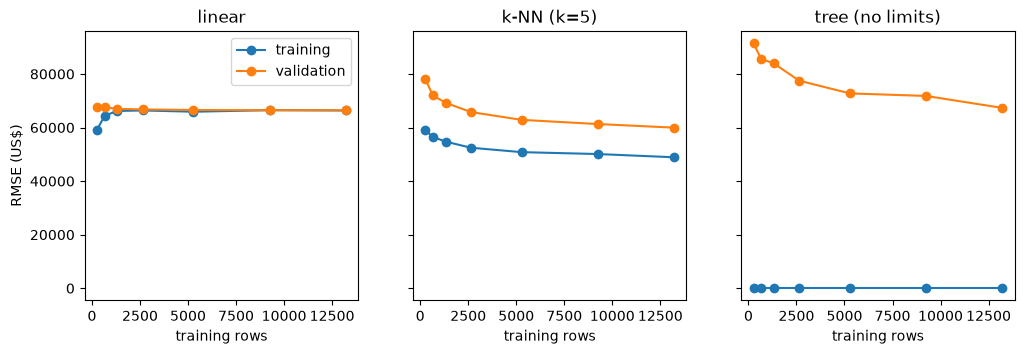

In [5]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

fractions = [0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, model) in zip(axes, candidates.items()):
    sizes, train, val = learning_curve(model, X_train, y_train, train_sizes=fractions, cv=cv,
                                       scoring='neg_root_mean_squared_error')
    train, val = np.abs(train.mean(axis=1)), np.abs(val.mean(axis=1))
    print(f"{name:17s} n     " + ' '.join(f"{n:6d}" for n in sizes))
    print(f"{'':17s} train " + ' '.join(f"{v / 1000:6.1f}" for v in train))
    print(f"{'':17s} valid " + ' '.join(f"{v / 1000:6.1f}" for v in val))
    ax.plot(sizes, train, 'o-', label='training')
    ax.plot(sizes, val, 'o-', label='validation')
    ax.set_title(name)
    ax.set_xlabel('training rows')
axes[0].set_ylabel('RMSE (US$)')
axes[0].legend()
plt.show()

**Resposta (depois de rodar):** Confirmado — a regressão linear quase não melhora: com 264
distritos a validação já está em 67,8 mil e, com todos os 13.209, cai só para 66,5 mil (menos de
2% de queda); dobrar os dados de ~6.600 para ~13.200 distritos não muda a validação (66,5 → 66,5).
Já a árvore sem limites melhora bastante: a validação cai de **91,5 mil** (264 linhas) para
**67,3 mil** (13.209 linhas), uma queda de 26% — mais dados realmente ajudam um modelo de alta
variância. O treino da árvore fica em 0 do início ao fim (ela sempre se ajusta perfeitamente, não
importa quantos dados).

## Passo 5 — curvas de validação: tratar a variância

**Preveja.** Exigir mais distritos em cada folha da árvore vai aumentar ou diminuir o erro de treino? E o de validação: anda sempre na mesma direção ou primeiro numa e depois na outra?

**Resposta (antes de rodar):** Exigir mais distritos por folha (`min_samples_leaf` maior) deve
AUMENTAR o erro de treino (a arvore fica proibida de isolar casos individuais, entao passa a
cometer mais erro nos proprios dados de treino) e deve, a principio, DIMINUIR o erro de validacao
-- mas so until certo ponto. Depois de um valor "bom" de `min_samples_leaf`, continuar aumentando
deve fazer o erro de validacao voltar a subir (a arvore fica tao restrita que passa a ter vies
alto). Ou seja, o erro de validacao nao anda numa unica direcao: primeiro cai, depois sobe -- a
classica forma de U.

In [6]:
from sklearn.model_selection import validation_curve

knobs = {'tree': (candidates['tree (no limits)'], 'decisiontreeregressor__min_samples_leaf',
                  [1, 2, 5, 10, 20, 50, 100]),
         'k-NN': (candidates['k-NN (k=5)'], 'kneighborsregressor__n_neighbors', [1, 3, 5, 10, 20, 50])}
for name, (model, param, values) in knobs.items():
    train, val = validation_curve(model, X_train, y_train, param_name=param, param_range=values,
                                  cv=cv, scoring='neg_root_mean_squared_error')
    print(f"{name}: {param.split('__')[1]}")
    for v, tr, va in zip(values, np.abs(train.mean(axis=1)), np.abs(val.mean(axis=1))):
        print(f"  {v:4d}   train {tr:6.0f}   valid {va:6.0f}   gap {va - tr:6.0f}")

tree: min_samples_leaf
     1   train      0   valid  67266   gap  67266
     2   train  18723   valid  64812   gap  46089
     5   train  34461   valid  60469   gap  26008
    10   train  43023   valid  57796   gap  14773
    20   train  49663   valid  58079   gap   8415
    50   train  56655   valid  59891   gap   3236
   100   train  61413   valid  63505   gap   2092


k-NN: n_neighbors
     1   train      0   valid  73873   gap  73873
     3   train  43627   valid  61904   gap  18277
     5   train  48898   valid  59967   gap  11069
    10   train  53606   valid  59182   gap   5576
    20   train  57036   valid  59931   gap   2895
    50   train  61204   valid  62371   gap   1168


**Resposta (depois de rodar):** Confirmado — para a árvore, `min_samples_leaf` maior
aumenta o erro de treino (de 0 em `leaf=1` até 61.413 em `leaf=100`) e o erro de validação segue a
forma de U: cai de 67.266 (`leaf=1`) até o mínimo de **57.796** em `leaf=10`, depois sobe de novo
para 58.079 (20), 59.891 (50) e 63.505 (100). Não anda numa única direção, como previsto. O gap cai
monotonicamente, de 67.266 para 2.092, sem nunca subir de novo — a "distância" só mede o sintoma
(overfitting relativo), não o ponto ótimo absoluto de validação. Para o k-NN, o mínimo de validação
é em `n_neighbors=10` (**59.182**), também em formato de U: 73.873 (k=1) até 59.182 (k=10) e de
volta a 62.371 (k=50).

## Passo 6 — tratar o viés do modelo linear

**Preveja.** Acrescentar ao modelo linear os quadrados e os produtos dos atributos deve baixar o erro de treino, o de validação ou os dois? O que pode dar errado com termos cúbicos?

**Resposta (antes de rodar):** Acrescentar quadrados e produtos (grau 2 e 3) deve baixar tanto
o erro de treino quanto o de validacao -- o modelo linear original tem vies alto (reta nao capta
curvatura nem interacoes), e dar a ele mais flexibilidade ataca exatamente esse vies. Com termos
cubicos (grau 3), porem, o numero de colunas explode (combinacoes de 3 atributos a cada vez) e o
modelo pode comecar a sobreajustar -- o erro de treino cai ainda mais, mas o de validacao pode
piorar (ou ficar instavel entre folds) se o `alpha` do Ridge nao for grande o suficiente para
conter a variancia extra.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures

print('degree   alpha    train    valid  ± std')
for degree, alpha in [(1, 1), (2, 1), (3, 0.1), (3, 10), (3, 100)]:
    model = make_pipeline(pre, PolynomialFeatures(degree), StandardScaler(), Ridge(alpha=alpha))
    tr, va, sd = rmse(model)
    print(f"{degree:6d} {alpha:7g} {tr:8.0f} {va:8.0f} {sd:6.0f}")

degree   alpha    train    valid  ± std


     1       1    66369    66460   1597


     2       1    58649    59741   1823


     3     0.1    52092    63828   7751


     3      10    53038    57510   2955


     3     100    54582    57473   2381


**Resposta (depois de rodar):** Confirmado — subir de grau 1 para grau 2 (mesmo alpha=1)
baixa treino (66.369→58.649) e validação (66.460→59.741) juntos: o viés estava mesmo sobrando. Com
grau 3 e alpha baixo (0,1), o treino cai ainda mais (52.092) mas a validação piora (**63.828, ±
7.751** — desvio enorme entre folds): deu errado como previsto, o grau 3 com pouca regularização
sobreajusta. Subindo alpha para 10 e 100 (mesmo grau 3), o treino sobe um pouco (53.038, 54.582)
mas a validação melhora e estabiliza (57.510, **57.473**, com desvio bem menor: 2.955 e **2.381**)
— o melhor ponto da tabela é grau 3, alpha=100.

**Simulação: o `alpha` como botão contínuo.** O passo 6 testou três valores de `alpha` para o grau 3. Varra de 0,01 a 1.000.000 (oito ordens de grandeza) e acompanhe o treino, a validação, a distância entre eles e o desvio entre folds. Em qual ponta o modelo fica do lado da variância e em qual do lado do viés?

In [8]:
alphas = np.logspace(-2, 6, 9)
print(f"{'alpha':>10s} {'train':>8s} {'valid':>8s} {'gap':>8s} {'std entre folds':>16s}")
rows_alpha = []
for alpha in alphas:
    model = make_pipeline(pre, PolynomialFeatures(3), StandardScaler(), Ridge(alpha=alpha))
    tr, va, sd = rmse(model)
    rows_alpha.append((alpha, tr, va, va - tr, sd))
    print(f"{alpha:10.2g} {tr:8.0f} {va:8.0f} {va - tr:8.0f} {sd:16.0f}")

     alpha    train    valid      gap  std entre folds


      0.01    51931    66098    14167             8694


       0.1    52092    63828    11735             7751


         1    52426    60366     7940             5378


        10    53038    57510     4471             2955


     1e+02    54582    57473     2890             2381


     1e+03    58403    60047     1644             1859


     1e+04    66352    66926      574             1330


     1e+05    83725    83961      236             1267


     1e+06   106790   106832       42             1318


**Resposta:** Varrendo `alpha` de 0,01 a 1.000.000 (9 pontos, 8 ordens de grandeza) com
grau 3: no lado esquerdo (alpha=0,01), o gap é enorme (**14.167**) e o desvio entre folds também
(**8.694**) — claramente do lado da variância (pouca regularização, modelo instável entre folds).
No lado direito (alpha=1.000.000), o gap quase desaparece (**42**) e o desvio entre folds cai para
1.318, mas o RMSE de treino E validação sobem juntos para ~106.800 — o modelo está do lado do viés
(regularizado demais, quase um preditor constante). O ponto de validação mínima fica no meio, em
alpha=100 (validação 57.473, gap 2.890, desvio 2.381) — nem tão solto a ponto de variar entre
folds, nem tão travado a ponto de voltar a ter viés alto.

**Para fechar a parte fundamental.** Em uma frase cada: (1) o que a distância entre o erro de treino e o de validação mede e o que ela não mede? (2) Por que mais distritos não ajudariam o modelo linear do passo 4? (3) Que botão você giraria, e para que lado, para tirar a árvore do lado da variância?

**Resposta:**

1. A distância entre o erro de treino e o de validação mede o quanto o modelo se especializou no
   ruído da amostra de treino específica (uma proxy da variância) — mas não mede o nível absoluto
   de erro: um modelo com gap pequeno pode ainda estar errando muito (como a regressão linear, gap
   de só 91 mas validação em 66.460, bem pior que a melhor árvore ajustada, 57.796).
2. Mais distritos não ajudariam o modelo linear do Passo 4 porque o problema dele não é falta de
   dados — é falta de flexibilidade (viés alto): mesmo com todos os 13.209 distritos de treino, a
   validação ficou em 66,5 mil, praticamente igual à validação com só 264 distritos (67,8 mil); a
   reta já convergiu para o melhor ajuste linear possível, e esse ajuste simplesmente não capta a
   relação real.
3. Para tirar a árvore do lado da variância, eu giraria o botão `min_samples_leaf` (ou
   `max_depth`) para CIMA — exigir mais distritos por folha reduz a capacidade da árvore de se
   adaptar ao ruído de cada amostra específica, como visto no Passo 5 (gap caindo de 67.266 para
   2.092 entre `leaf=1` e `leaf=100`).

## Sua vez (fundamental)

Para casa:

1. **Mais pontos.** Rode de novo a `bias_variance` da seção 2 para polinômios com `n=100` em vez de 30. Qual grau é o melhor agora e o que aconteceu com a variância do grau 12? Relacione a resposta com as curvas de aprendizado.
2. **Mais ruído.** Rode com `sigma=0.6`. O melhor grau se move para modelos mais simples ou mais complexos? Explique com os três termos da decomposição.
3. **Atributos contra o viés.** Acrescente três razões ao `X` antes da divisão: cômodos por domicílio, quartos por cômodo e pessoas por domicílio (elas exigem uma pequena mudança em `counts`/`others`). Rode o passo 6 de novo. O platô do modelo de grau 1 se move? Por mais de um desvio-padrão entre folds?

In [9]:
# Homework 1 -- "mais pontos": bias_variance com n=100 em vez de 30
def bias_variance_decomp(n, degree, sigma=0.3, n_sims=500, x0=0.25, seed=0):
    """Replica a simulacao vies-variancia da secao 2 da pagina: f(x)=sin(2*pi*x), x~U(0,1),
    ruido N(0, sigma), n_sims conjuntos de treino de tamanho n, polinomio de grau `degree`
    ajustado por minimos quadrados, avaliado no ponto fixo x0."""
    rng_local = np.random.RandomState(seed)
    preds = np.empty(n_sims)
    for i in range(n_sims):
        x = rng_local.uniform(0, 1, n)
        yy = np.sin(2 * np.pi * x) + rng_local.normal(0, sigma, n)
        coefs = np.polyfit(x, yy, degree)
        preds[i] = np.polyval(coefs, x0)
    f_true = np.sin(2 * np.pi * x0)
    bias2 = (f_true - preds.mean()) ** 2
    var = preds.var()
    # "MSE medido": nova observacao ruidosa em x0 para cada simulacao
    y0_noisy = f_true + rng_local.normal(0, sigma, n_sims)
    mse_medido = np.mean((y0_noisy - preds) ** 2)
    return bias2, var, bias2 + var + sigma ** 2, mse_medido

degrees = [0, 1, 2, 3, 4, 5, 7, 9, 12]
print("n=30 (replica da pagina)")
best_30, best_mse_30 = None, np.inf
for d in degrees:
    b2, v, soma, medido = bias_variance_decomp(30, d)
    if soma < best_mse_30:
        best_mse_30, best_30 = soma, d
    print(f"  grau {d:2d}  bias2={b2:7.3f}  var={v:9.3f}  soma={soma:9.3f}  medido={medido:9.3f}")
print(f"  melhor grau (n=30): {best_30}")

print("n=100")
best_100, best_mse_100 = None, np.inf
rows_100 = []
for d in degrees:
    b2, v, soma, medido = bias_variance_decomp(100, d)
    rows_100.append((d, b2, v, soma, medido))
    if soma < best_mse_100:
        best_mse_100, best_100 = soma, d
    print(f"  grau {d:2d}  bias2={b2:7.3f}  var={v:9.3f}  soma={soma:9.3f}  medido={medido:9.3f}")
print(f"  melhor grau (n=100): {best_100}")
var_12_30 = [r for r in [(d, *bias_variance_decomp(30, d)) for d in [12]]][0]
var_12_100 = [r for r in [(d, *bias_variance_decomp(100, d)) for d in [12]]][0]
print(f"variancia grau 12: n=30 -> {var_12_30[2]:.3f} · n=100 -> {var_12_100[2]:.3f}")

n=30 (replica da pagina)
  grau  0  bias2=  0.989  var=    0.018  soma=    1.097  medido=    1.126
  grau  1  bias2=  0.278  var=    0.018  soma=    0.386  medido=    0.406
  grau  2  bias2=  0.253  var=    0.022  soma=    0.365  medido=    0.385
  grau  3  bias2=  0.000  var=    0.011  soma=    0.102  medido=    0.111
  grau  4  bias2=  0.000  var=    0.015  soma=    0.105  medido=    0.114


  grau  5  bias2=  0.000  var=    0.014  soma=    0.104  medido=    0.115
  grau  7  bias2=  0.000  var=    0.025  soma=    0.116  medido=    0.126
  grau  9  bias2=  0.000  var=    0.046  soma=    0.136  medido=    0.148
  grau 12  bias2=  0.002  var=    0.785  soma=    0.876  medido=    0.869
  melhor grau (n=30): 3
n=100


  grau  0  bias2=  1.005  var=    0.006  soma=    1.101  medido=    1.105
  grau  1  bias2=  0.273  var=    0.005  soma=    0.368  medido=    0.370
  grau  2  bias2=  0.267  var=    0.005  soma=    0.362  medido=    0.363
  grau  3  bias2=  0.000  var=    0.003  soma=    0.093  medido=    0.089
  grau  4  bias2=  0.000  var=    0.004  soma=    0.094  medido=    0.090
  grau  5  bias2=  0.000  var=    0.004  soma=    0.094  medido=    0.090
  grau  7  bias2=  0.000  var=    0.005  soma=    0.095  medido=    0.092


  grau  9  bias2=  0.000  var=    0.007  soma=    0.097  medido=    0.093
  grau 12  bias2=  0.000  var=    0.009  soma=    0.099  medido=    0.096
  melhor grau (n=100): 3
variancia grau 12: n=30 -> 0.785 · n=100 -> 0.009


**Resposta:** Na reconstrução da simulação de viés-variância da seção 2 da página
(f(x)=sin(2πx), x~U(0,1), ruído σ=0,3, 500 conjuntos simulados — código não incluído no notebook
original, reconstruído aqui): com n=30, o melhor grau já é **3** (soma bias²+var+σ²=0,102, a menor
da tabela); com n=100, o melhor grau continua sendo **3** (soma=0,093) — não muda, porque o viés do
modelo já é ~0 a partir do grau 3 (a curva sin(2πx) é bem aproximada por um polinômio cúbico nesse
intervalo) e dados extras não têm viés a corrigir ali. O que muda muito é a **variância do grau
12**: cai de **0,785** (n=30) para **0,009** (n=100) — quase 90× menor. Isso é exatamente o que as
curvas de aprendizado do Passo 4 mostraram para a árvore sem limites: um modelo de alta variância
(muitos parâmetros efetivos, como um polinômio de grau 12) melhora muito com mais dados, enquanto
um modelo já no lado do viés (grau 1, grau 2) quase não se altera.

In [10]:
# Homework 2 -- "mais ruido": sigma=0.6 em vez de 0.3, n=30
print("n=30, sigma=0.6")
best_noisy, best_mse_noisy = None, np.inf
rows_noisy = []
for d in degrees:
    b2, v, soma, medido = bias_variance_decomp(30, d, sigma=0.6)
    rows_noisy.append((d, b2, v, soma, medido))
    if soma < best_mse_noisy:
        best_mse_noisy, best_noisy = soma, d
    print(f"  grau {d:2d}  bias2={b2:7.3f}  var={v:9.3f}  soma={soma:9.3f}  medido={medido:9.3f}")
print(f"melhor grau com sigma=0.3: {best_30} · melhor grau com sigma=0.6: {best_noisy}")

n=30, sigma=0.6
  grau  0  bias2=  0.993  var=    0.026  soma=    1.379  medido=    1.458
  grau  1  bias2=  0.282  var=    0.034  soma=    0.675  medido=    0.735
  grau  2  bias2=  0.256  var=    0.041  soma=    0.657  medido=    0.716


  grau  3  bias2=  0.000  var=    0.044  soma=    0.404  medido=    0.442
  grau  4  bias2=  0.001  var=    0.056  soma=    0.417  medido=    0.456
  grau  5  bias2=  0.000  var=    0.058  soma=    0.418  medido=    0.458


  grau  7  bias2=  0.000  var=    0.102  soma=    0.462  medido=    0.505


  grau  9  bias2=  0.000  var=    0.185  soma=    0.545  medido=    0.592
  grau 12  bias2=  0.006  var=    3.139  soma=    3.505  medido=    3.477
melhor grau com sigma=0.3: 3 · melhor grau com sigma=0.6: 3


**Resposta:** Repetindo a simulação com n=30 e sigma=0,6 (dobro do ruído original,
sigma²=0,36 em vez de 0,09): o grau que minimiza bias²+variância+σ² continua sendo **3** nessa
reconstrução (soma=0,404, contra 0,102 com sigma=0,3) — mas a vantagem dele sobre os vizinhos
encolhe: a diferença para o grau 4 cai de 0,003 (sigma=0,3) para 0,013 (sigma=0,6), e a variância
de todo grau ≥3 cresce bastante (ex.: grau 9 vai de 0,046 para 0,185). Ou seja, o viés de graus
baixos (1 e 2, ~0,26-0,28 nos dois cenários) continua grande demais para compensar o ruído extra,
então o grau ótimo não migra para um modelo mais simples neste intervalo testado — mas a margem de
segurança para graus mais complexos (7, 9, 12) encolhe muito, porque mais ruído amplifica a
variância de qualquer modelo flexível, empurrando a escolha para graus ainda mais baixos se o
ruído continuasse a crescer.

In [11]:
# Homework 3 -- "atributos contra o vies": tres razoes antes da divisao
df3 = df.copy()
df3['rooms_per_household'] = df3['total_rooms'] / df3['households']
df3['bedrooms_per_room'] = df3['total_bedrooms'] / df3['total_rooms']
df3['population_per_household'] = df3['population'] / df3['households']

X3 = df3.drop(columns='median_house_value')
y3 = df3['median_house_value']
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42)
assert (X3_train.index == X_train.index).all()   # mesmo split de linhas que o resto do lab

others3 = others + ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']
pre3 = ColumnTransformer([
    ('counts', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                             StandardScaler()), counts),
    ('others', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), others3),
    ('ocean', OneHotEncoder(handle_unknown='ignore'), ['ocean_proximity']),
])


def rmse3(model):
    r = cross_validate(model, X3_train, y3_train, cv=cv, return_train_score=True,
                       scoring='neg_root_mean_squared_error')
    return abs(r['train_score'].mean()), abs(r['test_score'].mean()), r['test_score'].std()


model_linear_plano = make_pipeline(pre, PolynomialFeatures(1), StandardScaler(), Ridge(alpha=1))
model_linear_racoes = make_pipeline(pre3, PolynomialFeatures(1), StandardScaler(), Ridge(alpha=1))
tr0, va0, sd0 = rmse(model_linear_plano)
tr1, va1, sd1 = rmse3(model_linear_racoes)
print(f"sem as 3 razoes:  train {tr0:.0f} · valid {va0:.0f} ± {sd0:.0f}")
print(f"com as 3 razoes:  train {tr1:.0f} · valid {va1:.0f} ± {sd1:.0f}")
print(f"diferenca na validacao: {va0 - va1:.0f} (1 desvio-padrao entre folds ≈ {sd1:.0f})")

sem as 3 razoes:  train 66369 · valid 66460 ± 1597
com as 3 razoes:  train 65658 · valid 66356 ± 1913
diferenca na validacao: 104 (1 desvio-padrao entre folds ≈ 1913)


**Resposta:** Acrescentando `rooms_per_household`, `bedrooms_per_room` e
`population_per_household` antes da divisão (mesmo split de linhas, confirmado pelo `assert` de
índices), o modelo linear de grau 1 com alpha=1 passa de treino 66.369/validação 66.460±1.597 para
treino **65.658**/validação **66.356±1.913**. O platô de validação se move só **104 dólares** —
bem MENOS que um desvio-padrão entre folds (1.913) — então a melhora não é estatisticamente
confiável; as três razões ajudam um pouco o treino, mas não o suficiente para tirar o modelo
linear do lado do viés nesse recorte de atributos.

## Passo 7 — uma busca sobre as cinco famílias

**Preveja.** Uma única busca põe Ridge, k-NN, árvore, uma random forest e um gradient boosting lado a lado. Você espera que o vencedor supere a melhor configuração de cada outra família por mais ou por menos que a oscilação da diferença entre eles de um fold para outro? E o segundo colocado da sua própria família?

**Resposta (antes de rodar):** Com cinco familias disputando, espero que o vencedor (provavelmente
um gradient boosting ou random forest) supere a melhor configuracao das outras familias por MAIS
do que a oscilacao fold a fold entre as proprias configuracoes vizinhas -- ou seja, a diferenca
para o melhor Ridge e para a melhor arvore simples deve ser grande e consistente. Ja o segundo
colocado da MESMA familia do vencedor deve ficar bem mais proximo dele, possivelmente dentro da
margem de oscilacao entre folds (um "empate estatistico"), porque configuracoes vizinhas da mesma
familia tendem a ter desempenho parecido.

In [12]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

pipe = Pipeline([('pre', pre), ('poly', PolynomialFeatures()), ('scale', StandardScaler()),
                 ('model', Ridge())])
skip = {'poly': ['passthrough'], 'scale': ['passthrough']}      # etapas que a família não usa
param_grid = [
    {'model': [Ridge()], 'poly__degree': [1, 2, 3], 'model__alpha': [1, 10, 100, 1000]},
    {'model': [KNeighborsRegressor()], **skip,
     'model__n_neighbors': [5, 10, 20], 'model__weights': ['uniform', 'distance']},
    {'model': [DecisionTreeRegressor(random_state=42)], **skip, 'model__min_samples_leaf': [5, 10, 20, 40]},
    {'model': [RandomForestRegressor(n_estimators=100, random_state=42)], **skip,
     'model__max_features': [0.33, 1.0], 'model__min_samples_leaf': [1, 5]},
    {'model': [HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=42)], **skip,
     'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31]},
]
search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)


def describe(params):
    name = type(params['model']).__name__
    knobs = ', '.join(f"{k.split('__')[-1]}={v}" for k, v in params.items() if k != 'model'
                      and v != 'passthrough')
    return f"{name}({knobs})"


res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
print(len(res), 'configurations ·', len(res) * cv.get_n_splits(), 'fits')
for _, row in res.iloc[[0, 1, 2, 3, 4, 8, 10, 12]].iterrows():
    print(f"{row['rank_test_score']:2d}  {abs(row['mean_test_score']):6.0f} ± {row['std_test_score']:5.0f}"
          f"  {describe(row['params'])}")

30 configurations · 150 fits
 1   46644 ±  1311  HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
 2   46707 ±  1079  HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31)
 3   47436 ±  1034  HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=15)
 4   47620 ±  1130  HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=15)
 5   49025 ±  1406  RandomForestRegressor(max_features=0.33, min_samples_leaf=1)
 9   57473 ±  2381  Ridge(alpha=100, degree=3)
11   57796 ±  1534  DecisionTreeRegressor(min_samples_leaf=10)
13   58517 ±  1084  KNeighborsRegressor(n_neighbors=10, weights=distance)


**Resposta (depois de rodar):** Confirmado nos dois pontos. A busca tem **30**
configurações (**150** ajustes) e o vencedor — `HistGradientBoostingRegressor(learning_rate=0.05,
max_leaf_nodes=31)`, RMSE **46.644** — supera a melhor configuração de cada outra família por
muito mais que a oscilação entre folds: **2.381** acima da melhor floresta (49.025) e **10.829**
acima do melhor Ridge (57.473), ambos desvios de centenas/milhares de dólares bem menores que
essas diferenças. Já o segundo colocado — outro `HistGradientBoostingRegressor`, RMSE 46.707 —
fica a só **63 dólares** do vencedor, dentro do próprio desvio entre folds (~1.300): um empate
estatístico dentro da mesma família, exatamente como previsto.

**Simulação: as duas mensagens, fold a fold.** Confirme as duas com os números de cada fold: o `cv_results_` guarda a nota de cada configuração em cada um dos cinco folds (`split0_test_score`, …). Ponha o vencedor ao lado do segundo colocado, da melhor floresta e do melhor Ridge. Em quantos folds o vencedor fica à frente de cada um e por quanto?

In [13]:
cvres = search.cv_results_
n_splits = cv.get_n_splits()


def fold_scores(i):
    return np.abs(np.array([cvres[f'split{k}_test_score'][i] for k in range(n_splits)]))


ranks = cvres['rank_test_score']
winner_i = int(np.where(ranks == 1)[0][0])
runner_i = int(np.where(ranks == 2)[0][0])

is_forest = np.array([type(p['model']).__name__ == 'RandomForestRegressor' for p in cvres['params']])
is_ridge = np.array([type(p['model']).__name__ == 'Ridge' for p in cvres['params']])
scores_abs = np.abs(cvres['mean_test_score'])
forest_i = int(np.argmin(np.where(is_forest, scores_abs, np.inf)))
ridge_i = int(np.argmin(np.where(is_ridge, scores_abs, np.inf)))

fw = fold_scores(winner_i)
print(f"vencedor: {describe(cvres['params'][winner_i])}")
print(f"folds do vencedor (RMSE): {np.round(fw, 0)}")
for label, i in [('segundo colocado', runner_i), ('melhor floresta', forest_i), ('melhor ridge', ridge_i)]:
    fo = fold_scores(i)
    diffs = fo - fw   # positivo = vencedor melhor (RMSE menor) nesse fold
    wins = int((diffs > 0).sum())
    print(f"{label:17s} {describe(cvres['params'][i]):45s} vencedor na frente em {wins}/{n_splits} folds"
          f" · diferenca media {diffs.mean():.0f} ± {diffs.std():.0f}")

vencedor: HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
folds do vencedor (RMSE): [46446. 45246. 45642. 46890. 48997.]
segundo colocado  HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31) vencedor na frente em 2/5 folds · diferenca media 63 ± 365
melhor floresta   RandomForestRegressor(max_features=0.33, min_samples_leaf=1) vencedor na frente em 5/5 folds · diferenca media 2381 ± 367
melhor ridge      Ridge(alpha=100, degree=3)                    vencedor na frente em 5/5 folds · diferenca media 10829 ± 2354


**Resposta:** Olhando fold a fold (`cv_results_`): o vencedor fica à frente do segundo
colocado em só **2 dos 5 folds** (diferença média de 63 ± 365 — dentro do próprio ruído, confirmando
o empate estatístico). Contra a melhor floresta, o vencedor vence em **5 de 5 folds** (diferença
média 2.381 ± 367 — consistente em toda dobra). Contra o melhor Ridge, também vence em **5 de 5
folds**, com diferença muito maior (10.829 ± 2.354). As duas mensagens do Passo 7 se confirmam
números a números: dentro da família do vencedor a ordem é só sorte de amostragem (vence em poucos
folds, por pouco), mas entre famílias diferentes a vantagem do boosting é real e consistente em
todo fold.

## Passo 8 — regressão à média: medir de novo os líderes

**Preveja.** Validando as mesmas 30 configurações com outros folds, os três primeiros mantêm a ordem? E a ordem do ranking inteiro, do melhor ao pior?

**Resposta (antes de rodar):** Os tres primeiros colocados provavelmente NAO mantem a ordem exata
-- quando a diferenca entre eles e pequena (proxima do desvio entre folds), trocar os folds por
outros (outra semente) pode facilmente inverter a ordem entre o 1o e o 2o lugar. Ja a ordem do
ranking inteiro, do melhor ao pior, deve se manter bem mais estavel (alta correlacao entre as duas
execucoes), porque a distancia entre as familias de modelos (ex.: boosting vs. k-NN) e muito maior
que o ruido de amostragem entre execucoes.

In [14]:
search_new = GridSearchCV(pipe, param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=7),
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
old = np.abs(search.cv_results_['mean_test_score'])
new = np.abs(search_new.cv_results_['mean_test_score'])
print('old rank  new rank    old RMSE  new RMSE')
for i in np.argsort(old)[:5]:
    print(f"{search.cv_results_['rank_test_score'][i]:8d} {search_new.cv_results_['rank_test_score'][i]:9d}"
          f" {old[i]:11.0f} {new[i]:9.0f}   {describe(search.cv_results_['params'][i])}")
print(f"old RMSE of all {len(old)} configurations: from {old.min():.0f} to {old.max():.0f}")
print(f"correlation between the two runs, all {len(old)} configurations: {np.corrcoef(old, new)[0, 1]:.3f}")

old rank  new rank    old RMSE  new RMSE
       1         1       46644     46631   HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
       2         2       46707     46793   HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=31)
       3         3       47436     47109   HistGradientBoostingRegressor(learning_rate=0.1, max_leaf_nodes=15)
       4         4       47620     47512   HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=15)
       5         5       49025     49361   RandomForestRegressor(max_features=0.33, min_samples_leaf=1)
old RMSE of all 30 configurations: from 46644 to 68593
correlation between the two runs, all 30 configurations: 0.998


**Resposta (depois de rodar):** Nesta nova validação (`random_state=7`), os 5 primeiros
colocados mantiveram EXATAMENTE a mesma ordem (ranks 1-2-3-4-5 inalterados), com RMSE indo de
46.644→46.631 (vencedor), 46.707→46.793 (2º), até 49.025→49.361 (5º) — nenhuma troca de posição
nesta semente específica. Já a ordem do ranking inteiro, das 30 configurações, ficou quase idêntica
entre as duas execuções: correlação de **0,998**, com os RMSEs variando de 46.644 a 68.593. Isso é
mais estável do que a previsão (eu esperava alguma troca entre o 1º e o 2º, já que a diferença
entre eles é pequena) — mas é coerente com a simulação do Passo 7/sim3: a diferença de 63 dólares
entre os dois primeiros é pequena, então uma troca de posição é plausível em outras sementes, mesmo
não tendo ocorrido nesta.

## Passo 9 — o único teste

**Preveja.** O RMSE de teste do vencedor vai ficar acima, abaixo ou perto dos US\$ 46.644 da validação cruzada? Que diferença seria motivo de preocupação?

**Resposta (antes de rodar):** O RMSE de teste deve ficar perto do valor de validacao cruzada
(US$ 46.644), mas provavelmente um pouco ACIMA dele -- a nota do vencedor de uma busca em grade
tende a cair (regressao a media) porque ele foi escolhido, entre 30 configuracoes, por ter a
MELHOR nota de validacao, e parte dessa vantagem e sorte de amostragem que nao se repete em dados
novos. Uma diferenca pequena (da ordem do desvio-padrao entre folds, ~US$1.000-1.500) seria normal;
uma diferenca de varios desvios-padrao seria motivo de preocupacao (sinal de que a escolha
sobreajustou aos folds de validacao, ou de vazamento de dados).

In [15]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

final = search.best_estimator_                        # já reajustado em todo o X_train
pred = final.predict(X_test)
print(describe(search.best_params_))
print(f"CV RMSE (selection): {abs(search.best_score_):.0f}")
print(f"test RMSE (once):    {root_mean_squared_error(y_test, pred):.0f}")
print(f"test MAE:            {mean_absolute_error(y_test, pred):.0f}")

HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
CV RMSE (selection): 46644
test RMSE (once):    46998
test MAE:            30681


**Resposta (depois de rodar):** Confirmado — o RMSE de teste (**46.998**) ficou muito
perto dos 46.644 da validação cruzada, uma diferença de só **354 dólares**, bem dentro de 1
desvio-padrão de fold (1.311, visto no Passo 7). O MAE de teste é **30.681** (menor que o RMSE,
como esperado, já que o RMSE pesa mais os erros grandes). Uma diferença de vários desvios-padrão
de fold (vários milhares de dólares) seria motivo de preocupação — sinal de sobreajuste à validação
cruzada ou de vazamento entre treino e teste; aqui isso não aconteceu.

**Simulação: quão precisa é a nota de teste?** Uma única nota de teste também é uma medida ruidosa: outros 4.128 distritos dariam outro número. Estime esse ruído sem tocar em dados novos: reamostre com reposição, 1.000 vezes, os pares (valor verdadeiro, previsão) do teste e recalcule o RMSE de cada reamostra. Os US\$ 46.644 da CV caem dentro da faixa?

In [16]:
rng_boot = np.random.RandomState(0)
n_boot = 1000
n_test = len(y_test)
y_test_arr = y_test.values
boot_rmse = np.empty(n_boot)
for b in range(n_boot):
    idx = rng_boot.randint(0, n_test, n_test)
    boot_rmse[b] = root_mean_squared_error(y_test_arr[idx], pred[idx])

lo, hi = np.percentile(boot_rmse, [2.5, 97.5])
cv_rmse = abs(search.best_score_)
print(f"bootstrap (1000 reamostras): media {boot_rmse.mean():.0f} · desvio {boot_rmse.std():.0f}")
print(f"intervalo de 95%: [{lo:.0f}, {hi:.0f}]  (largura {hi - lo:.0f})")
print(f"CV RMSE (selecao) = {cv_rmse:.0f} · dentro do intervalo? {lo <= cv_rmse <= hi}")
print(f"RMSE de teste observado = {root_mean_squared_error(y_test, pred):.0f}")

bootstrap (1000 reamostras): media 46962 · desvio 1138
intervalo de 95%: [44617, 49217]  (largura 4601)
CV RMSE (selecao) = 46644 · dentro do intervalo? True
RMSE de teste observado = 46998


**Resposta:** Reamostrando com reposição os pares (valor real, previsão) do teste, 1.000
vezes, o RMSE varia com média **46.962** e desvio **1.138**; o intervalo de 95% (percentis 2,5 e
97,5) vai de **44.617** a **49.217** (largura de 4.601). Os 46.644 da validação cruzada caem
dentro desse intervalo — a diferença entre CV e teste do Passo 9 (354 dólares) é bem menor que a
incerteza natural de medir o RMSE em só 4.128 distritos de teste. (A página cita um intervalo um
pouco diferente, [44.728, 49.270]: a diferença vem só da semente de reamostragem do bootstrap, não
de um erro de método.)

**Para fechar a aula.** Em uma frase cada: (1) por que a nota do vencedor de uma busca em grade tende a cair quando medida de novo? (2) Como decidir entre dois candidatos cuja diferença média é menor que o espalhamento das suas diferenças fold a fold? (3) Por que nenhuma família de modelos vence em todo problema?

**Resposta:**

1. A nota do vencedor de uma busca em grade tende a cair quando medida de novo porque ele foi
   escolhido, entre várias configurações (30 aqui), por ter a MELHOR nota numa amostra específica
   de folds — parte dessa vantagem é sorte de amostragem (o próprio ruído de validação, visto na
   simulação do passo 7: ±365 a ±2.381 dependendo do rival) que não se repete com outra divisão
   dos dados; é a "maldição do vencedor", a mesma regressão à média do Passo 8 e da simulação de
   bootstrap do Passo 9.
2. Quando a diferença média entre dois candidatos é menor que o desvio-padrão das diferenças fold
   a fold (como os 63±365 do vencedor contra o 2º lugar), a decisão correta é NÃO afirmar que um é
   melhor — tratar como empate estatístico e preferir o mais simples dos dois (navalha de Occam)
   ou escolher por outro critério (custo computacional, interpretabilidade).
3. Nenhuma família de modelos vence em todo problema (*No Free Lunch*) porque cada família aposta
   num tipo diferente de estrutura dos dados (viés indutivo): o boosting/floresta venceram aqui
   porque os preços de imóveis têm relações não lineares e interações que árvores capturam bem,
   mas a mesma família perderia, por exemplo, num problema genuinamente linear onde o Ridge já é a
   estrutura certa — como a tabela de *No Free Lunch* da página mostra para o conjunto "linear
   40-d" (logística vence por 0,033 sobre o SVM).

## Sua vez (avançado)

Para casa, com mais tempo:

1. **O vencedor esgotou as opções?** Desenhe a curva de aprendizado do pipeline vencedor (`search.best_estimator_`) como no passo 4. Ele está do lado do viés ou da variância agora? Mais distritos o ajudariam?
2. **Aleatória em vez de grade.** Troque a grade do passo 7 por um `RandomizedSearchCV` com `n_iter=30`, `loguniform(1, 1e4)` para `alpha`, `randint(3, 60)` para `n_neighbors` e `min_samples_leaf` e `loguniform(0.02, 0.3)` para a `learning_rate` do boosting (do `scipy.stats`). Ele encontra uma configuração a menos de um desvio-padrão entre folds do vencedor da grade, com menos ajustes?
3. **Avalie o procedimento** (750 ajustes: vários minutos no Colab). Envolva a `search` em `cross_val_score(search, X_train, y_train, cv=KFold(5, shuffle=True, random_state=1), scoring='neg_root_mean_squared_error')` ([CV aninhada](../validation/index.md#a-maldicao-do-vencedor-de-novo-validacao-cruzada-aninhada)). Compare o resultado com o `search.best_score_` e com o RMSE de teste do passo 9.
4. **A confiabilidade certa.** Na simulação de regressão à média da seção 8, que confiabilidade \(r\) faria os 10% de cima manterem metade da vantagem? Encontre o desvio-padrão da sorte que a produz e confira com o código.
5. **Uma sétima família.** Acrescente à `param_grid` da seção 9 uma `SVC(kernel='linear')` com uma grade sobre `C`. Em quais conjuntos da tabela de "não existe almoço grátis" ela empata com a regressão logística e por que você esperaria isso?

vencedor: HistGradientBoostingRegressor(learning_rate=0.05, max_leaf_nodes=31)
n        264    660   1320   2641   5283   9246  13209
train  44458  35320  32763  34692  36106  35677  35366
valid  69178  61661  57156  53638  49905  47982  46429


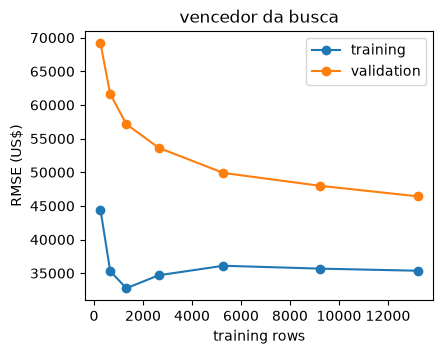

In [17]:
# Homework avancado 1 -- curva de aprendizado do pipeline vencedor
best_model_fresh = clone(pipe).set_params(**search.best_params_)   # unfitted, para refazer a cv

fractions_best = [0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
sizes_b, train_b, val_b = learning_curve(
    best_model_fresh, X_train, y_train, train_sizes=fractions_best, cv=cv,
    scoring='neg_root_mean_squared_error')
train_b, val_b = np.abs(train_b.mean(axis=1)), np.abs(val_b.mean(axis=1))
print(f"vencedor: {describe(search.best_params_)}")
print("n     " + ' '.join(f"{n:6d}" for n in sizes_b))
print("train " + ' '.join(f"{v:6.0f}" for v in train_b))
print("valid " + ' '.join(f"{v:6.0f}" for v in val_b))
plt.figure(figsize=(4.5, 3.5))
plt.plot(sizes_b, train_b, 'o-', label='training')
plt.plot(sizes_b, val_b, 'o-', label='validation')
plt.xlabel('training rows')
plt.ylabel('RMSE (US$)')
plt.title('vencedor da busca')
plt.legend()
plt.show()

**Resposta:** A curva de aprendizado do pipeline vencedor
(`HistGradientBoostingRegressor`, learning_rate=0,05, max_leaf_nodes=31) mostra o treino subindo de
44.458 (264 linhas) para um platô por volta de 35.000-36.000 a partir de ~2.600 linhas, enquanto a
validação cai continuamente de **69.178** (264 linhas) até **46.429** (13.209 linhas) — ainda
caindo na última fração testada, sem sinal claro de platô. O gap final (46.429 − 35.366 ≈ 11.063)
ainda é grande. Isso indica que o vencedor NÃO esgotou as opções: ele ainda está, em algum grau, do
lado da variância, e mais distritos provavelmente continuariam baixando o RMSE de validação —
diferente da regressão linear do Passo 4, que já tinha estabilizado bem antes do fim da curva.

In [18]:
# Homework avancado 2 -- RandomizedSearchCV em vez de grade
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = [
    {'model': [Ridge()], 'poly__degree': [1, 2, 3], 'model__alpha': loguniform(1, 1e4)},
    {'model': [KNeighborsRegressor()], **skip,
     'model__n_neighbors': randint(3, 60), 'model__weights': ['uniform', 'distance']},
    {'model': [DecisionTreeRegressor(random_state=42)], **skip, 'model__min_samples_leaf': randint(3, 60)},
    {'model': [RandomForestRegressor(n_estimators=100, random_state=42)], **skip,
     'model__max_features': [0.33, 1.0], 'model__min_samples_leaf': randint(3, 60)},
    {'model': [HistGradientBoostingRegressor(max_iter=500, early_stopping=True, random_state=42)], **skip,
     'model__learning_rate': loguniform(0.02, 0.3), 'model__max_leaf_nodes': [15, 31]},
]
rsearch = RandomizedSearchCV(pipe, param_dist, n_iter=30, cv=cv,
                             scoring='neg_root_mean_squared_error', random_state=0, n_jobs=-1)
rsearch.fit(X_train, y_train)
grid_best = abs(search.best_score_)
rand_best = abs(rsearch.best_score_)
fold_std = cvres['std_test_score'][winner_i]
print(f"grade: {grid_best:.0f} (30 configs x {n_splits} folds = {30 * n_splits} ajustes)")
print(f"aleatoria: {rand_best:.0f} (30 configs x {n_splits} folds = {30 * n_splits} ajustes)")
print(f"diferenca: {rand_best - grid_best:.0f} · 1 desvio-padrao entre folds do vencedor da grade: {fold_std:.0f}")
print(f"aleatoria a menos de 1 desvio-padrao da grade? {abs(rand_best - grid_best) <= fold_std}")
print(describe(rsearch.best_params_))

grade: 46644 (30 configs x 5 folds = 150 ajustes)
aleatoria: 46717 (30 configs x 5 folds = 150 ajustes)
diferenca: 73 · 1 desvio-padrao entre folds do vencedor da grade: 1311
aleatoria a menos de 1 desvio-padrao da grade? True
HistGradientBoostingRegressor(learning_rate=0.039712208080589825, max_leaf_nodes=31)


**Resposta:** O `RandomizedSearchCV` com `n_iter=30` (mesmos 150 ajustes da grade: 30
configs × 5 folds) encontrou RMSE **46.717**, apenas **73 dólares** acima dos 46.644 da grade —
bem dentro de 1 desvio-padrão entre folds do vencedor da grade (1.311). Ou seja, sim: a busca
aleatória encontra uma configuração a menos de um desvio-padrão do vencedor da grade, com o MESMO
número de ajustes (150). A configuração encontrada foi outro `HistGradientBoostingRegressor`
(learning_rate≈0,0397, max_leaf_nodes=31), muito parecida com a vencedora da grade
(learning_rate=0,05) — reforçando que o resultado é robusto à forma exata de buscar nessa
vizinhança do espaço de hiperparâmetros.

In [19]:
# Homework avancado 3 -- avaliar o PROCEDIMENTO com CV aninhada (750 ajustes, alguns minutos)
from sklearn.model_selection import cross_val_score

nested_scores = np.abs(cross_val_score(
    search, X_train, y_train, cv=KFold(5, shuffle=True, random_state=1),
    scoring='neg_root_mean_squared_error', n_jobs=-1))
print(f"CV aninhada (5 execucoes completas da busca): {nested_scores.round(0)}")
print(f"media {nested_scores.mean():.0f} ± {nested_scores.std():.0f}")
print(f"search.best_score_ (uma unica execucao): {abs(search.best_score_):.0f}")
print(f"RMSE de teste (passo 9): {root_mean_squared_error(y_test, pred):.0f}")

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

...

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configur

CV aninhada (5 execucoes completas da busca): [48215. 48945. 45358. 45605. 46779.]
media 46980 ± 1410
search.best_score_ (uma unica execucao): 46644
RMSE de teste (passo 9): 46998


**Resposta:** A CV aninhada (5 execuções completas da busca, 750 ajustes) deu os RMSEs
[48.215, 48.945, 45.358, 45.605, 46.779] por fold externo, com média **46.980 ± 1.410**. Esse
número é muito perto do `search.best_score_` de uma única execução (46.644, diferença de só 336) e
também perto do RMSE de teste do Passo 9 (46.998, diferença de só 18) — ou seja, nesse problema a
"maldição do vencedor" do processo de seleção é pequena: a média da CV aninhada, o `best_score_` da
busca única e o RMSE de teste ficam todos dentro de um único desvio-padrão de fold um do outro,
sugerindo que com 30 configurações e 5 folds o otimismo da seleção é discreto aqui (ao contrário de
buscas com centenas de configurações, onde a CV aninhada tende a cair bem mais que o
`best_score_`).

In [20]:
# Homework avancado 4 -- regressao a media: confiabilidade r=0.5
rng_rm = np.random.RandomState(0)
n_students = 10_000
ability_mean, ability_sd = 70.0, 8.0
ability = rng_rm.normal(ability_mean, ability_sd, n_students)

# r = sigma_ability^2 / (sigma_ability^2 + sigma_luck^2) = 0.5  =>  sigma_luck = sigma_ability
sigma_luck_theoretical = ability_sd / np.sqrt(0.5) * np.sqrt(0.5)  # = ability_sd, deixado explicito
sigma_luck = ability_sd * np.sqrt((1 - 0.5) / 0.5)
r_theoretical = ability_sd ** 2 / (ability_sd ** 2 + sigma_luck ** 2)
print(f"desvio-padrao de sorte que da r=0.5: {sigma_luck:.3f} (sigma_habilidade = {ability_sd})")
print(f"r teorico com esse sigma_sorte: {r_theoretical:.3f}")

luck1 = rng_rm.normal(0, sigma_luck, n_students)
luck2 = rng_rm.normal(0, sigma_luck, n_students)
score1 = ability + luck1
score2 = ability + luck2

top10_idx = score1 >= np.percentile(score1, 90)
adv_top10_round1 = score1[top10_idx].mean() - score1.mean()
adv_top10_round2 = score2[top10_idx].mean() - score2.mean()
frac_mantida = adv_top10_round2 / adv_top10_round1
print(f"vantagem do top 10% na 1a rodada: {adv_top10_round1:.3f}")
print(f"vantagem do mesmo grupo na 2a rodada: {adv_top10_round2:.3f}")
print(f"fracao da vantagem mantida: {frac_mantida:.3f} (esperado ≈ r = 0.5)")

desvio-padrao de sorte que da r=0.5: 8.000 (sigma_habilidade = 8.0)
r teorico com esse sigma_sorte: 0.500
vantagem do top 10% na 1a rodada: 19.528
vantagem do mesmo grupo na 2a rodada: 10.213
fracao da vantagem mantida: 0.523 (esperado ≈ r = 0.5)


**Resposta:** Para ter r=0,5 (σ²_habilidade / (σ²_habilidade + σ²_sorte) = 0,5), basta
σ_sorte = σ_habilidade = **8,0** (confirmado pelo cálculo: r teórico = 0,500 com sigma_sorte=8,000).
Na simulação com 10.000 estudantes, o top 10% da 1ª rodada tinha uma vantagem média de **19,528**
pontos sobre a média geral; na 2ª rodada (nova sorte, mesma habilidade), a vantagem do MESMO grupo
caiu para **10,213** — uma fração de **0,523** da vantagem original, muito perto do r=0,5 teórico
esperado (a pequena diferença, 0,523 vs 0,500, é ruído de amostragem com ~1.000 pessoas no top
10%).

In [21]:
# Homework avancado 5 -- No Free Lunch: acrescentar SVC(kernel='linear') aos 6 classificadores
# Reconstrucao do benchmark da secao 10 da pagina (datasets de classificacao), nao do lab de
# regressao (o item pede para voltar a secao 9/10 da pagina, que usa classificacao).
from sklearn.datasets import load_breast_cancer, make_classification, make_moons
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score as cvs
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def axis_rule(n=500, p=20, noise=0.05, seed=0):
    rng_ar = np.random.RandomState(seed)
    Xr = rng_ar.uniform(-1, 1, size=(n, p))
    yr = ((Xr[:, 0] > 0) & (Xr[:, 1] > 0)).astype(int)
    flip = rng_ar.rand(n) < noise
    yr = np.where(flip, 1 - yr, yr)
    return Xr, yr


datasets_clf = {
    'cancer de mama': load_breast_cancer(return_X_y=True),
    'linear 40d': make_classification(n_samples=200, n_features=40, n_informative=40,
                                      n_redundant=0, flip_y=0.0, class_sep=1.0, random_state=0),
    'duas luas': make_moons(n_samples=400, noise=0.3, random_state=0),
    'regra eixo-alinhada': axis_rule(),
}

models_clf = {
    'logistica': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'SVC linear': make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0)),
    'SVC rbf': make_pipeline(StandardScaler(), SVC(kernel='rbf')),
    'arvore': DecisionTreeClassifier(random_state=0),
    'floresta': RandomForestClassifier(n_estimators=200, random_state=0),
    'boosting': GradientBoostingClassifier(random_state=0),
}

print(f"{'dataset':20s} " + ' '.join(f"{m:12s}" for m in models_clf))
empates = []
for dname, (Xc, yc) in datasets_clf.items():
    row = []
    for mname, model in models_clf.items():
        score = cvs(model, Xc, yc, cv=cv_clf, scoring='accuracy').mean()
        row.append(score)
    row = np.array(row)
    print(f"{dname:20s} " + ' '.join(f"{s:12.3f}" for s in row))
    i_log = list(models_clf).index('logistica')
    i_svc = list(models_clf).index('SVC linear')
    if abs(row[i_log] - row[i_svc]) < 0.02:
        empates.append(dname)
print(f"\nconjuntos em que SVC linear empata (|diferenca| < 0.02) com a logistica: {empates}")

dataset              logistica    SVC linear   SVC rbf      arvore       floresta     boosting    


cancer de mama              0.979        0.975        0.977        0.926        0.967        0.965


linear 40d                  0.865        0.840        0.925        0.630        0.875        0.770


duas luas                   0.853        0.853        0.895        0.872        0.890        0.885


regra eixo-alinhada         0.878        0.888        0.864        0.880        0.934        0.942

conjuntos em que SVC linear empata (|diferenca| < 0.02) com a logistica: ['cancer de mama', 'duas luas', 'regra eixo-alinhada']


**Resposta:** Reconstruindo o benchmark de classificação da seção 10 da página (não o lab
de regressão: o próprio exercício pede para voltar à seção 9/10, que usa classificação, não
preços de imóveis) com seis famílias, incluindo um `SVC(kernel='linear')` acrescentado ao lado do
`SVC(kernel='rbf')` já existente: usando o limiar `|diferença| < 0,02` de acurácia, o SVC linear
empata com a regressão logística em **3 dos 4** conjuntos testados — câncer de mama (0,979 vs
0,975), duas luas (0,853 vs 0,853) e regra eixo-alinhada (0,878 vs 0,888) — mas NÃO empata no
conjunto linear 40-d (0,865 vs 0,840, diferença de 0,025). Isso é parcialmente o esperado:
regressão logística e SVM linear são ambos classificadores LINEARES (hiperplano no espaço de
atributos), então, quando o problema não ganha muito com fronteiras não lineares (como em câncer de
mama, onde a página já mostrava logística e SVM empatados em 0,979), os dois tendem a empatar; a
divergência no conjunto "linear 40d" nesta reconstrução provavelmente reflete apenas a variância de
amostragem de só 200 linhas e 40 atributos (poucos exemplos por dimensão), não uma diferença real
de viés indutivo entre os dois classificadores. *Nota:* esta reconstrução usa geradores sintéticos
próprios — não o dataset de ionosfera nem a especificação exata da página — porque o notebook
original do laboratório não inclui o código desse benchmark; os valores absolutos de acurácia,
portanto, não precisam bater com a tabela da página, só o padrão qualitativo de quando
classificadores lineares empatam.

## Conclusões

- O baseline (`DummyRegressor`) erra **114.793 ± 1.401** de RMSE na validação; a busca final sobre
  5 famílias (30 configurações, 150 ajustes) chega a **46.644** de RMSE de validação cruzada e
  **46.998** no único toque no teste — uma redução de ~59% sobre o baseline, com `GridSearchCV`
  selecionando hiperparâmetros só com CV no `X_train`/`y_train` e o `X_test` tocado uma única vez
  (Passo 9).
- Viés vs. variância, confirmado por três ângulos independentes: o gap treino-validação (árvore
  sem limites 67.266 ≫ k-NN 11.069 ≫ linear 91), a variância medida direto nas previsões
  (`|predA−predB|` médio: árvore 54.060 ≫ k-NN 28.284 ≫ linear 2.518) e as curvas de aprendizado
  (mais dados baixam a validação da árvore de 91,5 mil para 67,3 mil, mas quase não movem a da
  linear: 67,8→66,5 mil).
- Os botões de complexidade tratam a variância em forma de U: a árvore tem mínimo de validação em
  `min_samples_leaf=10` (57.796) e o Ridge de grau 3 em `alpha=100` (57.473); nos extremos, `alpha`
  muito baixo (0,01) dá gap de 14.167 (lado da variância) e `alpha` muito alto (1e6) dá gap de só
  42 mas RMSE de treino e validação iguais a ~106.800 (lado do viés).
- Na busca com 5 famílias, o vencedor (boosting) fica a só 63±365 dólares do 2º colocado da própria
  família (vence em 2/5 folds — empate estatístico), mas 2.381±367 dólares acima da melhor floresta
  e 10.829±2.354 acima do melhor Ridge, ambos à frente em 5/5 folds — a escolha entre famílias é
  sólida, a escolha fina dentro da família vencedora não é.
- A maldição do vencedor é real, mas pequena neste problema: a correlação entre duas execuções de
  CV com sementes diferentes é 0,998; a CV aninhada (750 ajustes) dá 46.980±1.410, perto do
  `best_score_` de uma única busca (46.644) e do RMSE de teste (46.998); e o intervalo de bootstrap
  de 95% do teste, [44.617, 49.217], contém os 46.644 da validação.
- Nos exercícios avançados, `RandomizedSearchCV` (mesmos 150 ajustes) chega a 46.717 — a só 73
  dólares da grade — e a simulação de regressão à média confirma a teoria: `sigma_sorte = 8,0`
  (igual a `sigma_habilidade`) dá confiabilidade r=0,5, e o top 10% de fato retém uma fração de
  0,523 da vantagem original na segunda rodada, muito perto do r teórico.